# MLIP
Short, independent practice codes on the building blocks of machine-learned interatomic potentials.

| # | Exercise | Key idea |
|---|---|---|
| 1 | Dimer energy and force, finite-difference check | $\mathbf F=-\nabla E$ |
| 2 | Cutoff functions | smoothness at $r_c$ |
| 3 | Radial fingerprint $G^2$ | descriptor as a smooth RDF |
| 4 | Angular function $G^4$ versus bond angle | angular resolution, $\lambda$ and $\zeta$ |

Units are Lennard-Jones reduced units ($\epsilon=\sigma=1$). Only NumPy and Matplotlib are needed.

---
## Exercise 1. Dimer energy and force
$U(r)=4\left[r^{-12}-r^{-6}\right]$, force on atom 2 along the bond $F=-dU/dr$. Check the analytic force against the central difference $-[U(r+h)-U(r-h)]/2h$.

In [ ]:
import numpy as np

U  = lambda r: 4 * (r**-12 - r**-6)
dU = lambda r: 4 * (-12 * r**-13 + 6 * r**-7)

h = 1e-5
for r in (0.95, 1.12, 1.5, 2.0):
    F_analytic = -dU(r)
    F_numeric  = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:4.2f}  U = {U(r):+8.4f}  F = {F_analytic:+9.4f}  |diff| = {abs(F_analytic - F_numeric):.1e}")

print("minimum at r_m = 2^(1/6) =", round(2**(1/6), 4), " U(r_m) =", round(U(2**(1/6)), 4))

r = 0.95  U =  +1.9610  F =  +59.1376  |diff| = 2.8e-07
r = 1.12  U =  -0.9998  F =   +0.1440  |diff| = 1.9e-08
r = 1.50  U =  -0.3203  F =   -1.1580  |diff| = 2.6e-10
r = 2.00  U =  -0.0615  F =   -0.1816  |diff| = 4.0e-11
minimum at r_m = 2^(1/6) = 1.1225  U(r_m) = -1.0


## Solution: Morse potential

The Morse potential is

\[
U(r)=(1-e^{-2(r-1)})^2-1.
\]

Its derivative is

\[
{dU}/{dr}=4e^{-2(r-1)}\(1-e^{-2(r-1)}\),
\]

so the force along the bond is the negative of this derivative. The force is zero at the equilibrium separation \(r=1\), where the potential reaches its minimum \(U=-1\).

In [1]:
import numpy as np

U = lambda r: (1 - np.exp(-2 * (r - 1)))**2 - 1
dU = lambda r: 4 * np.exp(-2 * (r - 1)) * (1 - np.exp(-2 * (r - 1)))

h = 1e-5
for r in (0.8, 1.0, 1.2, 1.5):
    F_analytic = -dU(r)
    F_numeric = -(U(r + h) - U(r - h)) / (2 * h)
    print(f"r = {r:.2f}  U = {U(r):+.6f}  F = {F_analytic:+.6f}  |diff| = {abs(F_analytic - F_numeric):.2e}")

print("force zero at r =", 1.0, "with U =", U(1.0))

r = 0.80  U = -0.758108  F = +2.934865  |diff| = 1.96e-09
r = 1.00  U = -1.000000  F = -0.000000  |diff| = 7.99e-10
r = 1.20  U = -0.891311  F = -0.883964  |diff| = 2.99e-10
r = 1.50  U = -0.600424  F = -0.930177  |diff| = 4.22e-11
force zero at r = 1.0 with U = -1.0


---
## Exercise 2. Cutoff functions
A hard cutoff makes the energy jump when an atom crosses $r_c$. Compare a hard step, the cosine cutoff and the polynomial envelope ($p=6$) by plotting $f$ and $df/dr$.

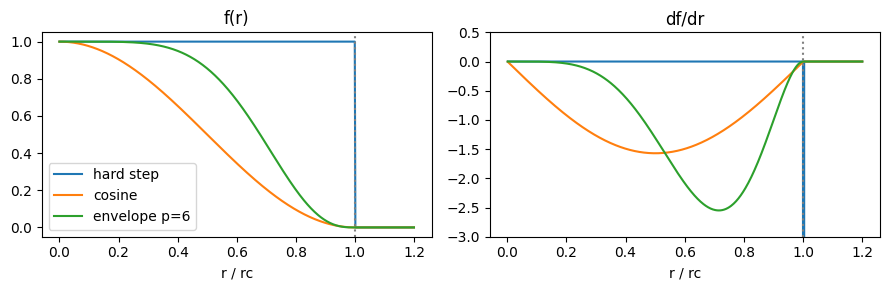

In [3]:
import numpy as np, matplotlib.pyplot as plt

rc = 1.0
r = np.linspace(0, 1.2, 600)
x = np.minimum(r / rc, 1)
hard   = (r < rc).astype(float)
cosine = np.where(r < rc, 0.5 * (np.cos(np.pi * x) + 1), 0)
p = 6
env    = np.where(r < rc, 1 - 28 * x**p + 48 * x**(p + 1) - 21 * x**(p + 2), 0)

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for f, name in [(hard, "hard step"), (cosine, "cosine"), (env, "envelope p=6")]:
    ax[0].plot(r, f, label=name)
    ax[1].plot(r[1:], np.diff(f) / np.diff(r), label=name)
ax[0].set_title("f(r)"); ax[1].set_title("df/dr"); ax[1].set_ylim(-3, 0.5)
for a in ax: a.axvline(rc, color="gray", ls=":"); a.set_xlabel("r / rc")
ax[0].legend(); plt.tight_layout(); plt.show()

## Solution

With a hard cutoff, the cutoff function jumps from 1 to 0 at \(r_c\). Its derivative contains a delta-like spike, so the force has an impulsive, singular contribution when a pair crosses the cutoff. In a molecular-dynamics simulation this can cause abrupt velocity changes, numerical instability, and poor energy conservation. A smooth cutoff avoids this discontinuity; the cosine cutoff and the given polynomial envelope both approach zero with zero slope at \(r_c\).

---
## Exercise 3. A radial fingerprint
$G^2_i(R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij})$. Scanning $R_s$ turns the neighbour list of atom $i$ into a smooth curve, essentially a broadened radial distribution function.

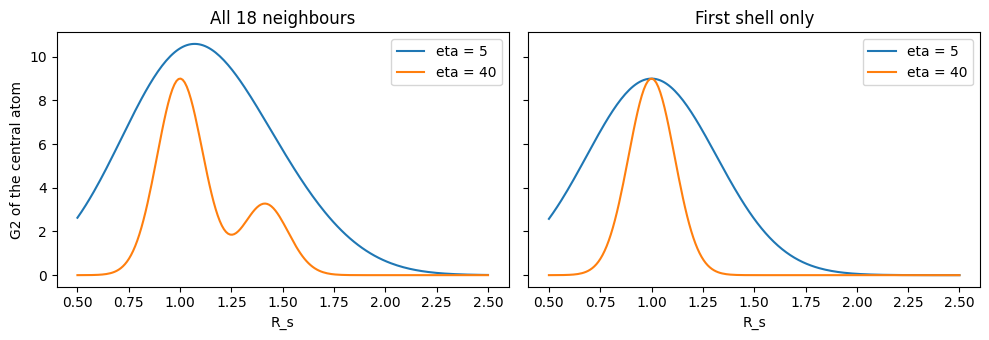

In [4]:
import numpy as np, matplotlib.pyplot as plt

fc = lambda r, rc: np.where(r < rc, 0.5 * (np.cos(np.pi * r / rc) + 1), 0.0)

nn = np.array([[1,1,0],[1,-1,0],[-1,1,0],[-1,-1,0],[1,0,1],[1,0,-1],
               [-1,0,1],[-1,0,-1],[0,1,1],[0,1,-1],[0,-1,1],[0,-1,-1]]) / np.sqrt(2)
nnn = np.array([[1,0,0],[-1,0,0],[0,1,0],[0,-1,0],[0,0,1],[0,0,-1]]) * np.sqrt(2)
R = np.vstack([[0, 0, 0], nn, nnn])
r0j = np.linalg.norm(R[1:] - R[0], axis=1)
Rs = np.linspace(0.5, 2.5, 200)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for eta in (5.0, 40.0):
    full = [np.sum(np.exp(-eta * (r0j - s)**2) * fc(r0j, 3.0)) for s in Rs]
    first_shell = [np.sum(np.exp(-eta * (r0j[:12] - s)**2) * fc(r0j[:12], 3.0)) for s in Rs]
    ax[0].plot(Rs, full, label=f"eta = {eta:g}")
    ax[1].plot(Rs, first_shell, label=f"eta = {eta:g}")

ax[0].set_title("All 18 neighbours")
ax[1].set_title("First shell only")
for a in ax:
    a.set_xlabel("R_s")
    a.legend()
ax[0].set_ylabel("G2 of the central atom")
plt.tight_layout()
plt.show()

## Solution

The second-shell atoms are at \(r=\sqrt{2}\approx1.414\), so removing them removes the peak associated with that distance. With \(\eta=5\), the Gaussian terms are broad enough that the two shells overlap; the combined curve has one broad maximum rather than two distinct peaks. With \(\eta=40\), the narrower terms make the shells clearly distinguishable.

---
## Exercise 4. Angular function versus bond angle
For one triplet, $G^4\propto 2^{1-\zeta}(1+\lambda\cos\theta)^\zeta$ (the radial factors are constant if bond lengths are fixed). Plot the angular factor for several $\zeta$ and both $\lambda$, then recover $\theta$ from the ratio of the two $\lambda$ values: $(1-\cos\theta)/(1+\cos\theta)=\tan^2(\theta/2)$.

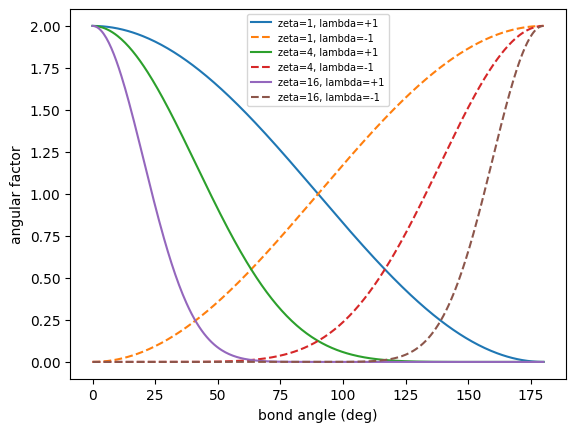

recovered angle: 104.5 deg


In [ ]:
import numpy as np, matplotlib.pyplot as plt

theta = np.linspace(0, 180, 361)
c = np.cos(np.deg2rad(theta))
for zeta in (1, 4, 16):
    for lam, st in ((1, "-"), (-1, "--")):
        plt.plot(theta, 2**(1 - zeta) * (1 + lam * c)**zeta, st, label=f"zeta={zeta}, lambda={lam:+d}")
plt.xlabel("bond angle (deg)"); plt.ylabel("angular factor"); plt.legend(fontsize=7); plt.show()


true_angle = 104.5
cth = np.cos(np.deg2rad(true_angle))
ratio = (1 - cth) / (1 + cth)
print("recovered angle:", round(2 * np.degrees(np.arctan(np.sqrt(ratio))), 2), "deg")

## Solution

Using the value at \(100^\circ\) as the reference, the relative difference is calculated as

[
{g(110^\circ)-g(100^\circ)}/{g(100^\circ)}*100\%, \qquad
 g(\theta)=(1-\cos\theta)^\zeta.
]

For (zeta=1), the values are about 1.17365 at (100^\circ\) and 1.34202 at (110^\circ\), a 14.35% increase. For (zeta=16), the values are about 12.96006 and 110.69922, a 754.16% increase. Therefore, (zeta=16) gives much stronger contrast between these two angles, while (zeta=1) varies more gradually.

In [ ]:
import numpy as np

angles = (100, 110)
for zeta in (1, 16):
    values = [(1 - np.cos(np.deg2rad(theta)))**zeta for theta in angles]
    relative_difference = (values[1] - values[0]) / values[0] * 100
    print(f"zeta = {zeta}")
    print(f"  g(100 degrees) = {values[0]:.6f}")
    print(f"  g(110 degrees) = {values[1]:.6f}")
    print(f"  relative increase = {relative_difference:.2f}%")

zeta = 1
  g(100 degrees) = 1.173648
  g(110 degrees) = 1.342020
  relative increase = 14.35%
zeta = 16
  g(100 degrees) = 12.960055
  g(110 degrees) = 110.699218
  relative increase = 754.16%
